<a href="https://colab.research.google.com/github/siyaagarwal2005/sepsis-prediction-using-LSTM/blob/main/4_model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook IV — Model Training

---

**Project:** AI-Based Sepsis Early Warning System  
**Dataset:** PhysioNet Challenge 2019  
**Author:** *Siya Agarwal*  
**Date:** *06 March, 2026*

---

### Purpose
Design, compile, and train an LSTM-based binary classifier that predicts sepsis onset
within a 6-hour window. This notebook covers:
1. Load pre-built sequences from Notebook III
2. Define the LSTM architecture
3. Compile with appropriate loss, optimizer, and metrics
4. Train with class weighting to handle imbalance
5. Plot training history
6. Save the trained model

### Inputs
- `processed_data/X_train.npy`, `y_train.npy`
- `processed_data/X_test.npy`, `y_test.npy`
- `processed_data/class_weights.npy`

### Outputs
- `models/lstm_sepsis_model.keras` — trained model
- `results/training_history.png` — loss and AUROC curves

### Architecture Summary
```
Input        : (6 timesteps, 15 features)
LSTM(64)     : return_sequences=True  — learns temporal patterns, passes full sequence forward
Dropout(0.3) : regularisation — prevents overfitting
LSTM(32)     : return_sequences=False — compresses sequence into single vector
Dropout(0.3) : regularisation
Dense(16)    : non-linear feature combination
Dense(1)     : sigmoid output — probability of sepsis in next hour
```

### ⚠️ GPU Required
Before running: `Runtime → Change runtime type → T4 GPU`

### Next Notebook
- `V_evaluation.ipynb` — AUROC, precision, recall, confusion matrix, threshold analysis

---
## Section 0 — Setup

Mount Drive, import libraries, and verify GPU is available.  
Training on CPU with 1M+ sequences would take hours. GPU cuts this to ~20–40 minutes.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.metrics import AUC

# ── Project paths ──────────────────────────────────────────────────────────────
BASE_PATH      = '/content/drive/MyDrive/sepsis_project/'
PROCESSED_PATH = BASE_PATH + 'processed_data/'
MODELS_PATH    = BASE_PATH + 'models/'
RESULTS_PATH   = BASE_PATH + 'results/'

os.makedirs(MODELS_PATH,  exist_ok=True)
os.makedirs(RESULTS_PATH, exist_ok=True)

# ── Reproducibility ────────────────────────────────────────────────────────────
RANDOM_SEED = 42
tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# ── GPU check ─────────────────────────────────────────────────────────────────
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f'GPU detected: {gpus[0].name}')
else:
    print('WARNING: No GPU detected. Go to Runtime → Change runtime type → T4 GPU')

GPU detected: /physical_device:GPU:0


---
## Section 1 — Load Sequences

Load the `.npy` arrays saved by Notebook III.  
No preprocessing happens here — data arrives ready to train.

In [ ]:
X_train = np.load(PROCESSED_PATH + 'X_train.npy')
y_train = np.load(PROCESSED_PATH + 'y_train.npy')
X_test  = np.load(PROCESSED_PATH + 'X_test.npy')
y_test  = np.load(PROCESSED_PATH + 'y_test.npy')
weights = np.load(PROCESSED_PATH + 'class_weights.npy')

class_weight_dict = {0: weights[0], 1: weights[1]}

print('=== Loaded Arrays ===')
print(f'X_train : {X_train.shape}   dtype={X_train.dtype}')  # expect (~1.2M, 6, 15)
print(f'y_train : {y_train.shape}   dtype={y_train.dtype}')
print(f'X_test  : {X_test.shape}    dtype={X_test.dtype}')
print(f'y_test  : {y_test.shape}    dtype={y_test.dtype}')
print(f'\nClass weights : {class_weight_dict}')
print(f'Sepsis rate in train: {y_train.mean()*100:.2f}%')

=== Loaded Arrays ===
X_train : (1046988, 6, 15)   dtype=float32
y_train : (1046988,)   dtype=float32
X_test  : (263206, 6, 15)    dtype=float32
y_test  : (263206,)    dtype=float32

Class weights : {0: np.float64(0.5095432162814307), 1: np.float64(26.696618899484932)}
Sepsis rate in train: 1.87%


---
## Section 2 — LSTM Architecture

### Why this architecture?

**Two LSTM layers (stacked)**  
The first LSTM (`return_sequences=True`) passes its full output at every timestep
to the second LSTM. This allows the second layer to learn higher-order temporal
patterns — not just what happened at each hour, but how the trends between hours relate.
Think of it as: first layer reads individual words, second layer reads the sentence.

**Dropout (0.3)**  
Randomly deactivates 30% of neurons during each training step. This forces the network
to not rely on any single neuron, preventing overfitting on the training set.

**Dense(16) → Dense(1, sigmoid)**  
The Dense(16) layer combines the LSTM output non-linearly.  
The final sigmoid neuron squashes the output to [0, 1] — a probability score.
A value of 0.8 means: "80% probability of sepsis onset in the next hour."

**Why not a larger model?**  
With 1.2M training sequences and a 3-day deadline, a lightweight model trains fast,
generalises well, and is easier to interpret. Larger is not always better.

In [ ]:
# ── Extract input dimensions from data ────────────────────────────────────────
# WINDOW_SIZE = 6 (timesteps), N_FEATURES = 15
_, WINDOW_SIZE, N_FEATURES = X_train.shape

# ── Build model ───────────────────────────────────────────────────────────────
model = Sequential([

    Input(shape=(WINDOW_SIZE, N_FEATURES)),

    # First LSTM layer — return_sequences=True passes full sequence to next layer
    LSTM(64, return_sequences=True),
    Dropout(0.3),   # 30% dropout for regularisation

    # Second LSTM layer — compresses sequence into a single context vector
    LSTM(32, return_sequences=False),
    Dropout(0.3),

    # Dense layer — non-linear feature combination
    Dense(16, activation='relu'),

    # Output layer — sigmoid produces probability [0, 1]
    Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 6, 64)          │        20,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,441 (130.63 KB)

 Trainable params: 33,441 (130.63 KB)

 Non-trainable params: 0 (0.00 B)

---
## Section 3 — Compile the Model

### Loss: Binary Cross-Entropy
Standard loss for binary classification. Penalises confident wrong predictions heavily.
For a sepsis prediction of 0.9 when the true label is 0, the penalty is large.
For a prediction of 0.51 when the label is 1, the penalty is also large — the model
was barely above chance when it should have been confident.

### Optimizer: Adam
Adam (Adaptive Moment Estimation) adjusts the learning rate for each parameter
individually during training. It is the standard optimizer for LSTMs — converges
faster and more stably than plain SGD.

### Metrics: AUROC
We track AUROC during training, not accuracy. Accuracy is misleading on imbalanced
data — a model predicting 'no sepsis' always scores 92.7% accuracy.
AUROC measures the model's ability to *rank* sepsis cases above non-sepsis cases,
independent of any threshold.

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=[
        AUC(name='auroc', curve='ROC'),   # primary metric
        'accuracy'                          # tracked for reference only
    ]
)

print('Model compiled.')
print(f'Optimizer : Adam (lr=0.001)')
print(f'Loss      : binary_crossentropy')
print(f'Metrics   : AUROC, accuracy')

Model compiled.
Optimizer : Adam (lr=0.001)
Loss      : binary_crossentropy
Metrics   : AUROC, accuracy


---
## Section 4 — Callbacks

Callbacks are functions that run automatically at the end of each training epoch.
We use three:

**EarlyStopping**  
Stops training when validation AUROC stops improving for 5 consecutive epochs.
Prevents wasting time on epochs that add nothing, and prevents overfitting.
`restore_best_weights=True` means the final model is the best one seen, not the last one.

**ModelCheckpoint**  
Saves the model to Drive every time validation AUROC improves.
Protects against Colab runtime crashes during long training runs.
If your session dies at epoch 18, the best model up to that point is already saved.

**ReduceLROnPlateau**  
If validation AUROC plateaus for 3 epochs, halves the learning rate.
A smaller learning rate helps the model make finer adjustments when it is close
to a good solution but keeps oscillating around it.

In [ ]:
MODEL_SAVE_PATH = MODELS_PATH + 'lstm_sepsis_model.keras'

callbacks = [

    EarlyStopping(
        monitor='val_auroc',
        patience=5,                  # stop after 5 epochs of no improvement
        mode='max',                  # we want AUROC to go UP
        restore_best_weights=True,   # revert to best epoch weights at end
        verbose=1
    ),

    ModelCheckpoint(
        filepath=MODEL_SAVE_PATH,
        monitor='val_auroc',
        save_best_only=True,         # only overwrite if this epoch is better
        mode='max',
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor='val_auroc',
        factor=0.5,                  # halve the learning rate
        patience=3,                  # after 3 stagnant epochs
        mode='max',
        min_lr=1e-6,                 # never go below this learning rate
        verbose=1
    )
]

print('Callbacks defined.')
print(f'Model will be saved to: {MODEL_SAVE_PATH}')

Callbacks defined.
Model will be saved to: /content/drive/MyDrive/sepsis_project/models/lstm_sepsis_model.keras


---
## Section 5 — Train the Model

### class_weight
We pass `class_weight_dict` to `model.fit()`. This tells Keras to multiply the loss
for sepsis samples by the class weight value (approximately 6–7x the non-sepsis weight).
The model is penalised much more for missing a sepsis case than for a false alarm.
Without this, the model would learn to predict 'no sepsis' always and call it a day.

### validation_split=0.1
Reserves 10% of training sequences as a validation set during training.
This is used by the callbacks to monitor performance — it is **not** the test set.
The test set (from Notebook II/III) is held out entirely until Notebook V.

### Expected training time
With GPU: ~20–40 minutes for 20 epochs.  
EarlyStopping may stop before 20 epochs if AUROC plateaus.

In [ ]:
print('Starting training...')
print(f'Training samples : {len(X_train):,}')
print(f'Class weights    : {class_weight_dict}\n')

history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=512,           # large batch for speed on GPU
    validation_split=0.1,     # 10% of train for validation monitoring
    class_weight=class_weight_dict,
    callbacks=callbacks,
    verbose=1
)

print('\nTraining complete.')

Starting training...
Training samples : 1,046,988
Class weights    : {0: np.float64(0.5095432162814307), 1: np.float64(26.696618899484932)}

Epoch 1/20
1841/1841 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7501 - auroc: 0.7641 - loss: 0.5821
Epoch 1: val_auroc improved from -inf to 0.80650, saving model to /content/drive/MyDrive/sepsis_project/models/lstm_sepsis_model.keras
1841/1841 ━━━━━━━━━━━━━━━━━━━━ 22s 9ms/step - accuracy: 0.7501 - auroc: 0.7642 - loss: 0.5821 - val_accuracy: 0.8204 - val_auroc: 0.8065 - val_loss: 0.4444 - learning_rate: 0.0010
Epoch 2/20
1839/1841 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7613 - auroc: 0.8135 - loss: 0.5320
Epoch 2: val_auroc did not improve from 0.80650
1841/1841 ━━━━━━━━━━━━━━━━━━━━ 17s 9ms/step - accuracy: 0.7613 - auroc: 0.8135 - loss: 0.5320 - val_accuracy: 0.8122 - val_auroc: 0.8050 - val_loss: 0.4328 - learning_rate: 0.0010
Epoch 3/20
1841/1841 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7620 - auroc: 0.8329 - loss: 0.5076
Epoc

---
## Section 6 — Training History Plots

We plot loss and AUROC over epochs for both training and validation sets.

**What good training looks like:**
- Both train and val loss decrease together → model is learning
- Both train and val AUROC increase together → generalisable improvement

**Warning signs:**
- Train loss drops but val loss rises → overfitting
- AUROC flatlines after epoch 2–3 → model may be stuck; try lower learning rate
- Wildly oscillating curves → batch size too small or learning rate too high

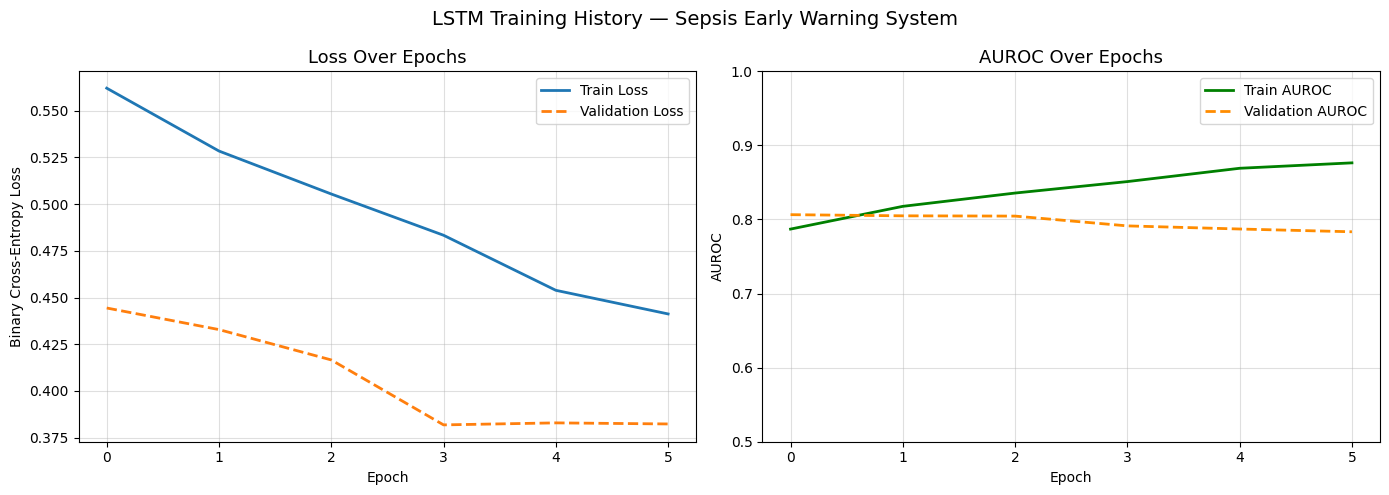

Plot saved to: /content/drive/MyDrive/sepsis_project/results/training_history.png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Loss curve ────────────────────────────────────────────────────────────────
axes[0].plot(history.history['loss'],     label='Train Loss',      linewidth=2)
axes[0].plot(history.history['val_loss'], label='Validation Loss', linewidth=2, linestyle='--')
axes[0].set_title('Loss Over Epochs', fontsize=13)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary Cross-Entropy Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.4)

# ── AUROC curve ───────────────────────────────────────────────────────────────
axes[1].plot(history.history['auroc'],     label='Train AUROC',      linewidth=2, color='green')
axes[1].plot(history.history['val_auroc'], label='Validation AUROC', linewidth=2, linestyle='--', color='darkorange')
axes[1].set_title('AUROC Over Epochs', fontsize=13)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('AUROC')
axes[1].set_ylim([0.5, 1.0])
axes[1].legend()
axes[1].grid(True, alpha=0.4)

plt.suptitle('LSTM Training History — Sepsis Early Warning System', fontsize=14)
plt.tight_layout()

# Save to Drive
plot_path = RESULTS_PATH + 'training_history.png'
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Plot saved to: {plot_path}')

---
## Section 7 — Quick Test Set Evaluation

A preliminary evaluation on the held-out test set to confirm the model is not
completely broken before moving to Notebook V.

**Note:** This is not the full evaluation. Notebook V will compute AUROC curves,
precision-recall, confusion matrix, and threshold analysis.  
Here we just want a quick sanity number.

**Expected range:** AUROC between 0.75 and 0.88 on PhysioNet 2019 is typical
for LSTM-based sepsis prediction in the literature.

In [ ]:
# ── Evaluate on test set ───────────────────────────────────────────────────────
test_results = model.evaluate(X_test, y_test, batch_size=512, verbose=0)
test_loss    = test_results[0]
test_auroc   = test_results[1]
test_acc     = test_results[2]

print('=== Test Set Results ===')
print(f'Loss     : {test_loss:.4f}')
print(f'AUROC    : {test_auroc:.4f}')   # primary metric — target > 0.75
print(f'Accuracy : {test_acc:.4f}')     # reference only — not our primary metric

# ── Generate probability predictions for Notebook V ───────────────────────────
# model.predict() returns raw probabilities — shape (n_sequences, 1)
# We flatten to 1D for easier handling in evaluation
y_pred_proba = model.predict(X_test, batch_size=512, verbose=0).flatten()

# Save predictions for Notebook V
np.save(PROCESSED_PATH + 'y_pred_proba.npy', y_pred_proba)
print(f'\nPrediction probabilities saved to processed_data/y_pred_proba.npy')
print(f'Prediction shape : {y_pred_proba.shape}')
print(f'Prediction range : [{y_pred_proba.min():.4f}, {y_pred_proba.max():.4f}]')

=== Test Set Results ===
Loss     : 0.5001
AUROC    : 0.7965
Accuracy : 0.7878

Prediction probabilities saved to processed_data/y_pred_proba.npy
Prediction shape : (263206,)
Prediction range : [0.0142, 0.9342]


---
## Section 8 — Save Final Model

The ModelCheckpoint callback already saved the best model during training.
Here we explicitly save the final model state as well, and confirm the file exists on Drive.

In [ ]:
# Save final model (ModelCheckpoint saved best already — this is a belt-and-suspenders save)
final_model_path = MODELS_PATH + 'lstm_sepsis_final.keras'
model.save(final_model_path)

print('=== Model Saved ===')
print(f'Best model (checkpoint) : {MODEL_SAVE_PATH}')
print(f'Final model             : {final_model_path}')

# Confirm file sizes
for path in [MODEL_SAVE_PATH, final_model_path]:
    if os.path.exists(path):
        size_mb = os.path.getsize(path) / 1e6
        print(f'{os.path.basename(path):<35}: {size_mb:.2f} MB')
    else:
        print(f'{path} — NOT FOUND')

=== Model Saved ===
Best model (checkpoint) : /content/drive/MyDrive/sepsis_project/models/lstm_sepsis_model.keras
Final model             : /content/drive/MyDrive/sepsis_project/models/lstm_sepsis_final.keras
lstm_sepsis_model.keras            : 0.44 MB
lstm_sepsis_final.keras            : 0.44 MB


---
## Summary

### Architecture
A two-layer stacked LSTM with dropout regularisation, followed by a dense output layer
with sigmoid activation. Input shape: `(6, 15)`. Output: sepsis risk probability ∈ [0, 1].

### Training Strategy
- **Loss:** Binary cross-entropy
- **Optimizer:** Adam (lr=0.001, reduced on plateau)
- **Class weighting:** Applied to penalise missed sepsis predictions
- **Early stopping:** Monitored validation AUROC with patience=5
- **Batch size:** 512 (optimised for GPU throughput)

### Outputs
- Trained model saved to `models/`
- Training history plot saved to `results/`
- Prediction probabilities saved to `processed_data/y_pred_proba.npy`

---
## Next Steps — `V_evaluation.ipynb`

1. Load `y_test.npy` and `y_pred_proba.npy`
2. Plot ROC curve and compute AUROC
3. Plot Precision-Recall curve
4. Generate confusion matrix at threshold = 0.5
5. Compute precision, recall, F1-score
6. Analyse threshold sensitivity — clinical tradeoff between false alarms and missed cases